# Market-Risk VaR Engine — Day 4
## P&L Attribution Test (PLAT)

Backtesting (Day 3) checks whether VaR is the right **size**. PLAT checks
something subtler: whether the risk model captures the **right risk factors**
at all. It's an FRTB requirement — and one almost no portfolio project includes.

The bank computes P&L two ways:

- **Hypothetical P&L (HPL)** — the "true" P&L from fully revaluing the actual
  positions with actual market moves. Reality.
- **Risk-theoretical P&L (RTPL)** — the P&L predicted by the **risk model**,
  using only the risk factors that model tracks.

If the model captures the important factors, HPL and RTPL move together closely.
If they diverge, the model is **missing risk factors** — and PLAT is the test
that formally detects it. A model can pass backtesting yet fail PLAT, because
it has the right *size* but the wrong *risk picture*.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## Rebuild the book and returns (Day 1)

In [2]:
PORTFOLIO = {
    "AAPL": (1_000_000, +1),
    "JPM": (750_000, +1),
    "SPY": (2_000_000, -1),
    "FXE": (1_500_000, +1),
    "FXY": (1_000_000, -1),
    "TLT": (1_250_000, +1),
}
START_DATE, END_DATE = "2019-01-01", "2024-12-31"


def signed_notionals():
    return pd.Series({t: n * d for t, (n, d) in PORTFOLIO.items()})


def make_synthetic_prices():
    dates = pd.bdate_range(START_DATE, END_DATE)
    n = len(dates)
    ann_vol = {
        "AAPL": 0.30,
        "JPM": 0.28,
        "SPY": 0.18,
        "FXE": 0.08,
        "FXY": 0.10,
        "TLT": 0.13,
    }
    beta = {"AAPL": 1.1, "JPM": 1.0, "SPY": 1.0, "FXE": 0.1, "FXY": -0.1, "TLT": -0.3}
    market = np.random.normal(0, 0.01, n)
    rets = {
        t: beta[t] * market + np.random.normal(0, ann_vol[t] / np.sqrt(252), n)
        for t in PORTFOLIO
    }
    return 100 * np.exp(pd.DataFrame(rets, index=dates).cumsum())


try:
    import yfinance as yf

    raw = yf.download(
        list(PORTFOLIO),
        start=START_DATE,
        end=END_DATE,
        auto_adjust=True,
        progress=False,
    )["Close"]
    prices = raw[list(PORTFOLIO)].dropna()
    if prices.empty:
        raise RuntimeError("empty")
    SOURCE = "real (Yahoo Finance)"
except Exception as e:
    prices = make_synthetic_prices()
    SOURCE = f"synthetic ({type(e).__name__})"

returns = np.log(prices / prices.shift(1)).dropna()
w = signed_notionals()
print(f"Data source: {SOURCE}  |  {len(returns):,} days")

Data source: real (Yahoo Finance)  |  1,508 days


## 1. Hypothetical P&L (HPL) — the truth

HPL is the full P&L using **all** instruments and their actual moves. This is
exactly the portfolio P&L from Day 1 — the "ground truth" against which the
risk model is judged.


In [3]:
def hypothetical_pnl(returns, w):
    """Full-revaluation P&L using all risk factors (the truth)."""
    return pd.Series(
        returns[w.index].values @ w.values, index=returns.index, name="HPL"
    )


hpl = hypothetical_pnl(returns, w)
print(f"HPL: mean {hpl.mean():,.0f}, std {hpl.std():,.0f}")

HPL: mean 558, std 17,871


## 2. Risk-theoretical P&L (RTPL) — the model's view

In a real bank, RTPL comes from a simplified risk model that tracks a chosen
set of risk factors. To make PLAT concrete, we build **two** versions of the
risk model:

- **Good model:** captures all the main instruments. Its RTPL should track HPL
  closely -> PLAT pass.
- **Poor model:** **omits a material risk factor** (the large short SPY
  position) **and mis-weights** the equity sensitivities (a stale-beta risk
  model). Its RTPL diverges from HPL -> PLAT fail.

This is precisely the situation PLAT exists to catch: a model that looks
plausible but is missing a real source of risk.


In [4]:
def risk_theoretical_pnl(returns, w, omit=None, factor_scale=None, noise=0.0, seed=0):
    "P&L from a risk model that may misrepresent the factors."
    used = w.copy()
    if omit:
        used = used.drop(omit)
    if factor_scale:
        for t, s in factor_scale.items():
            if t in used.index:
                used[t] = used[t] * s
    base = returns[used.index].values @ used.values
    if noise:
        rng = np.random.default_rng(seed)
        base = base + rng.normal(0, noise * base.std(), len(base))
    return pd.Series(base, index=returns.index, name="RTPL")


rtpl_good = risk_theoretical_pnl(returns, w, noise=0.02)


rtpl_poor = risk_theoretical_pnl(
    returns,
    w,
    omit=["SPY"],
    factor_scale={"AAPL": 0.5, "JPM": 0.5},
    noise=0.05,
)

print(f"Good RTPL: std {rtpl_good.std():,.0f}")
print(f"Poor RTPL: std {rtpl_poor.std():,.0f}  (omits SPY + mis-weighted betas)")

Good RTPL: std 17,876
Poor RTPL: std 19,273  (omits SPY + mis-weighted betas)


## 3. The two FRTB metrics

FRTB specifies two statistics comparing HPL and RTPL:

**Spearman correlation** — do the two series move together in rank? Robust to
outliers. **Higher is better.** Pass ~>= 0.80, fail ~< 0.70.

**Kolmogorov-Smirnov (KS)** — do the two series share the same distribution?
It's the max distance between their cumulative distributions. **Lower is
better.** Pass ~<= 0.09, fail ~> 0.12.

A desk stays in the favourable internal-models treatment only if **both** are
acceptable.


In [5]:
def plat_metrics(hpl, rtpl):
    """Compute the two FRTB PLAT statistics comparing HPL and RTPL."""
    spearman, _ = stats.spearmanr(hpl, rtpl)
    ks_stat, _ = stats.ks_2samp(hpl, rtpl)
    return spearman, ks_stat


def plat_zone(spearman, ks):
    """FRTB-style PLAT zone from the two metrics (illustrative thresholds)."""
    if spearman >= 0.80 and ks <= 0.09:
        return "GREEN (pass)"
    if spearman < 0.70 or ks > 0.12:
        return "RED (fail)"
    return "AMBER (watch)"


for name, rtpl in [("Good model", rtpl_good), ("Poor model (broken)", rtpl_poor)]:
    sp, ks = plat_metrics(hpl, rtpl)
    zone = plat_zone(sp, ks)
    print(f"{name:24s}  Spearman {sp:.3f}  |  KS {ks:.3f}  ->  {zone}")

Good model                Spearman 1.000  |  KS 0.006  ->  GREEN (pass)
Poor model (broken)       Spearman 0.736  |  KS 0.034  ->  AMBER (watch)


/home/vaibhav/github-cleanup/.venv-risk/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  outputs = ufunc(*args, out=...)


### Reading the result

The **good model** tracks HPL closely — high Spearman, low KS, PLAT pass. The
**poor model**, by dropping the rates position, has an RTPL that no longer
matches the true P&L's distribution and co-movement, so its metrics deteriorate
toward (or into) the fail zone. That's PLAT doing its job: detecting a model
that is missing a genuine risk factor, even though nothing about it looked
obviously broken.

(On real data the divergence is typically even sharper, since the omitted
and mis-weighted factors behave quite differently across regimes.)


## 4. Visualize the attribution

The clearest way to see PLAT: scatter RTPL against HPL. A good model hugs the
45-degree line; a poor model scatters away from it.


/home/vaibhav/github-cleanup/.venv-risk/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  outputs = ufunc(*args, out=...)


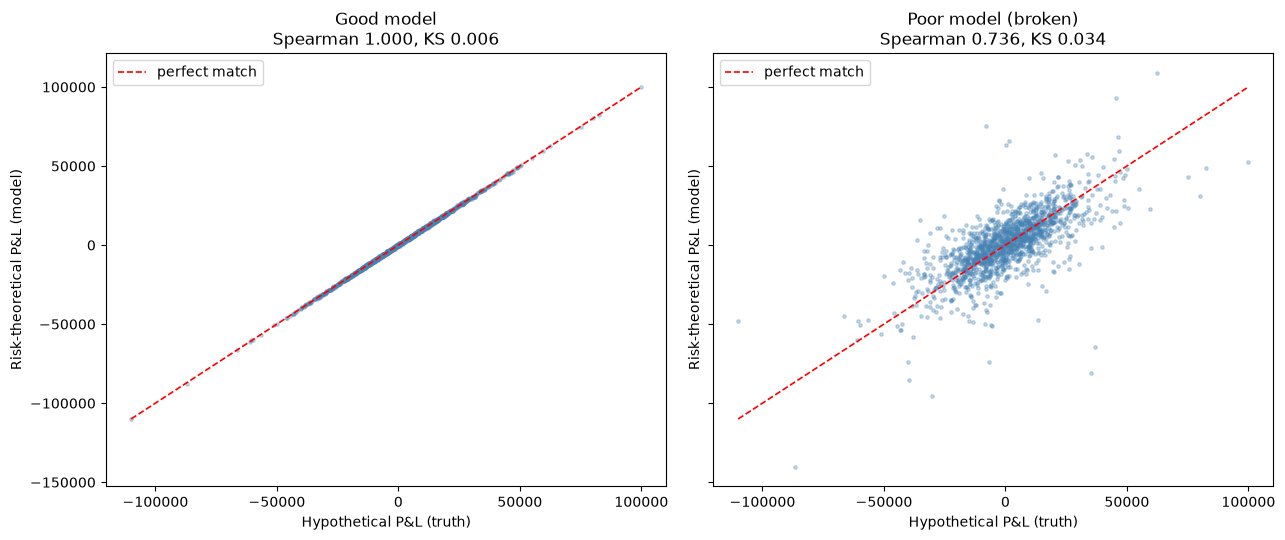

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, (name, rtpl) in zip(
    axes, [("Good model", rtpl_good), ("Poor model (broken)", rtpl_poor)]
):
    sp, ks = plat_metrics(hpl, rtpl)
    ax.scatter(hpl, rtpl, s=6, alpha=0.3, color="steelblue")
    lim = [hpl.min(), hpl.max()]
    ax.plot(lim, lim, color="red", lw=1.2, ls="--", label="perfect match")
    ax.set_title(f"{name}\nSpearman {sp:.3f}, KS {ks:.3f}")
    ax.set_xlabel("Hypothetical P&L (truth)")
    ax.set_ylabel("Risk-theoretical P&L (model)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. A combined PLAT report

The deliverable: a small table any risk manager can read at a glance.


In [7]:
def plat_report(hpl, models: dict):
    rows = []
    for name, rtpl in models.items():
        sp, ks = plat_metrics(hpl, rtpl)
        rows.append(
            {
                "model": name,
                "spearman": sp,
                "ks_stat": ks,
                "zone": plat_zone(sp, ks),
            }
        )
    return pd.DataFrame(rows).set_index("model")


report = plat_report(
    hpl,
    {
        "good (all factors)": rtpl_good,
        "poor (broken model)": rtpl_poor,
    },
)
report

,spearman,ks_stat,zone
model,,,
good (all factors),0.9997,0.0060,GREEN (pass)
poor (broken model),0.7359,0.0345,AMBER (watch)


## Day 4 summary

We built the **P&L Attribution Test**, the FRTB check that the risk model's P&L
tracks the true P&L:

1. **HPL** — full-revaluation truth.
2. **RTPL** — the risk model's P&L, with a good version and a deliberately
   factor-omitting poor version.
3. **Spearman correlation** (rank co-movement; higher better) and **KS
   statistic** (distributional match; lower better) — the two FRTB metrics.
4. A **PLAT report** classifying each model green/amber/red.

PLAT catches what backtesting can't: a model that is the right *size* but built
on an incomplete set of risk factors — the very gap that motivates RNIV.

**Day 5:** pulling the engine together — figures, a consolidated risk report,
and tests — before the model documentation on Day 6.
